# CCD distortion (tree-ring) maps -- paper figure F4

Plots the CCD-distortion maps used by `py_files/brick_ringmaps.py` (`ringmaps.fits`, built in April 2024; see PLAN.md):
per CCD and filter, the median offset (measured minus Gaia-predicted position, after the DCR correction) of Gaia stars
in 16 x 16 pixel bins, for the x and y pixel directions.

1. One CCD in detail (F4).
2. The whole focal plane in one band: every CCD has its own ring pattern, centred wherever the centre of the silicon
   boule was -- unrelated to the CCD's position in the focal plane.

Light: only reads the 65 MB map file, so it runs on a login node.

In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('py_files'), '..')))
from py_files import brick_ringmaps
from py_files import plot_style as ps
ps.apply()

PLOTS = '../writeup/plots/'
PIXSCALE = 262.          # mas per pixel
NX, NY = 2048, 4096      # CCD size in pixels
VLIM = 30                # colour-scale limit, mas

# focal-plane offsets of each CCD (same table as the lateral-colour model): focal-plane coords = pixel - crpix
crpixes = json.load(open('../py_files/lateral_model_poly3.json'))['crpixes']

maps = brick_ringmaps.get_ringmaps(brick_ringmaps.RINGMAPS_PATH)   # (ccd, band) -> (dx, dy) in pixels, (256, 128) bins
ccds = sorted({c for c, b in maps}, key=lambda c: (c[0], int(c[1:])))
print(f'{len(maps)} maps, {len(ccds)} CCDs')

def offsets_mas(ccd, band):
    """(dx, dy) in mas with empty bins masked."""
    dx, dy = maps[(ccd, band)]
    empty = (dx == 0) & (dy == 0)
    return (np.ma.masked_where(empty, dx * PIXSCALE), np.ma.masked_where(empty, dy * PIXSCALE))

cmap = ps.DIVERGING   # shared colour-blind-safe diverging map; grey = no data

244 maps, 61 CCDs


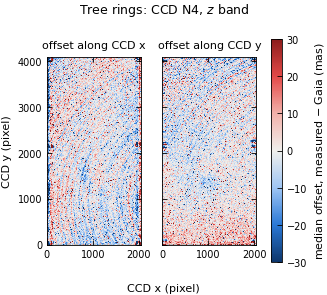

In [2]:
# F4: one CCD in detail
CCD, BAND = 'N4', 'z'
dx, dy = offsets_mas(CCD, BAND)
fig, axes = plt.subplots(1, 2, figsize=(ps.COLUMN, 3.0), sharey=True, constrained_layout=True)
for ax, img, comp in zip(axes, (dx, dy), ('x', 'y')):
    im = ax.imshow(img, origin='lower', extent=(0, NX, 0, NY), cmap=cmap, vmin=-VLIM, vmax=VLIM,
                   interpolation='nearest')
    ax.set_title(f'offset along CCD {comp}')
    ax.set_xticks([0, 1000, 2000])
    ax.set_yticks(range(0, 4001, 1000))
axes[0].set_ylabel('CCD y (pixel)')
fig.supxlabel('CCD x (pixel)', fontsize=8)
fig.colorbar(im, ax=axes, shrink=0.9, pad=0.02, label='median offset, measured $-$ Gaia (mas)')
fig.suptitle(f'Tree rings: CCD {CCD}, ${BAND}$ band')
plt.savefig(PLOTS + f'ringmap_{CCD}_{BAND}.pdf')

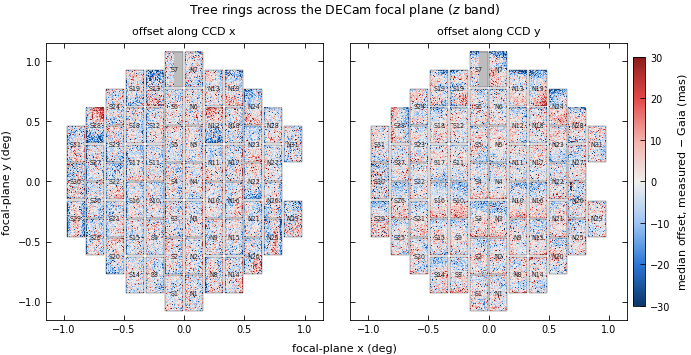

In [3]:
# Focal-plane view: all CCDs in one band, each at its position in the focal plane (Dustin's suggestion).
# Axes in degrees from the optical axis (0.262 arcsec/pixel). Grey = no data.
BAND = 'z'
DEG = PIXSCALE / 1000 / 3600
fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 3.6), sharey=True, constrained_layout=True)
for ax, k, comp in zip(axes, (0, 1), ('x', 'y')):
    for ccd in ccds:
        if (ccd, BAND) not in maps:
            continue
        x0, y0 = -crpixes[ccd][0], -crpixes[ccd][1]
        img = offsets_mas(ccd, BAND)[k]
        im = ax.imshow(img, origin='lower', extent=(x0 * DEG, (x0 + NX) * DEG, y0 * DEG, (y0 + NY) * DEG),
                       cmap=cmap, vmin=-VLIM, vmax=VLIM, interpolation='nearest')
        ax.add_patch(Rectangle((x0 * DEG, y0 * DEG), NX * DEG, NY * DEG, fill=False, lw=0.3, ec='0.3'))
        ax.text((x0 + NX / 2) * DEG, (y0 + NY / 2) * DEG, ccd, ha='center', va='center', fontsize=4.5, color='0.15')
    ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15); ax.set_aspect('equal')
    ax.set_title(f'offset along CCD {comp}')
axes[0].set_ylabel('focal-plane y (deg)')
fig.colorbar(im, ax=axes, shrink=0.9, pad=0.01, label='median offset, measured $-$ Gaia (mas)')
fig.supxlabel('focal-plane x (deg)', fontsize=8)
fig.suptitle(f'Tree rings across the DECam focal plane (${BAND}$ band)')
plt.savefig(PLOTS + f'ringmap_focal_plane_{BAND}.png', dpi=600)